In [5]:
pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from scipy.sparse import hstack, csr_matrix

# Load dataset
df = pd.read_csv("spam.csv", encoding="latin-1")

# Keep only the required columns
df = df[["v1", "v2"]].copy()

# Rename columns
df.columns = ["label", "message"]

# Remove missing values and duplicates
df = df.dropna()
df = df.drop_duplicates().reset_index(drop=True)

# Convert labels to numbers: ham = 0, spam = 1
df["label"] = df["label"].map({"ham": 0, "spam": 1})

print(df.head())
print("\nDataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5169, 2)

Label distribution:
label
0    4516
1     653
Name: count, dtype: int64


In [7]:
# Feature 1: Message length
df["message_length"] = df["message"].apply(len)

# Feature 2: Number of digits
df["num_digits"] = df["message"].apply(
    lambda text: sum(char.isdigit() for char in text)
)

# Feature 3: Number of capital letters
df["num_capitals"] = df["message"].apply(
    lambda text: sum(char.isupper() for char in text)
)

print(df[[
    "message",
    "message_length",
    "num_digits",
    "num_capitals",
    "label"
]].head(10))

                                             message  message_length  \
0  Go until jurong point, crazy.. Available only ...             111   
1                      Ok lar... Joking wif u oni...              29   
2  Free entry in 2 a wkly comp to win FA Cup fina...             155   
3  U dun say so early hor... U c already then say...              49   
4  Nah I don't think he goes to usf, he lives aro...              61   
5  FreeMsg Hey there darling it's been 3 week's n...             148   
6  Even my brother is not like to speak with me. ...              77   
7  As per your request 'Melle Melle (Oru Minnamin...             160   
8  WINNER!! As a valued network customer you have...             158   
9  Had your mobile 11 months or more? U R entitle...             154   

   num_digits  num_capitals  label  
0           0             3      0  
1           0             2      0  
2          25            10      1  
3           0             2      0  
4           0         

In [8]:
X = df["message"]
y = df["label"]

# First split: 60% training, 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining percentage:", round(len(X_train) / len(df) * 100, 2))
print("Validation percentage:", round(len(X_val) / len(df) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2))

Training samples: 3101
Validation samples: 1034
Testing samples: 1034

Training percentage: 59.99
Validation percentage: 20.0
Testing percentage: 20.0


In [9]:
tfidf = TfidfVectorizer(max_features=1000)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nNumber of vocabulary features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (3101, 1000)
Validation TF-IDF shape: (1034, 1000)
Testing TF-IDF shape: (1034, 1000)

Number of vocabulary features: 1000


In [10]:
numeric_columns = [
    "message_length",
    "num_digits",
    "num_capitals"
]

# Match each split's rows to the original dataframe
train_df = df.loc[X_train.index]
val_df = df.loc[X_val.index]
test_df = df.loc[X_test.index]

# Extract numerical features
X_train_num = train_df[numeric_columns].to_numpy(dtype=float)
X_val_num = val_df[numeric_columns].to_numpy(dtype=float)
X_test_num = test_df[numeric_columns].to_numpy(dtype=float)

# Standardize numeric features using training statistics only
num_mean = X_train_num.mean(axis=0)
num_std = X_train_num.std(axis=0)
num_std[num_std == 0] = 1

X_train_num = (X_train_num - num_mean) / num_std
X_val_num = (X_val_num - num_mean) / num_std
X_test_num = (X_test_num - num_mean) / num_std

# Combine TF-IDF and numeric features
X_train_final = hstack([
    X_train_tfidf,
    csr_matrix(X_train_num)
]).tocsr()

X_val_final = hstack([
    X_val_tfidf,
    csr_matrix(X_val_num)
]).tocsr()

X_test_final = hstack([
    X_test_tfidf,
    csr_matrix(X_test_num)
]).tocsr()

print("Final training features:", X_train_final.shape)
print("Final validation features:", X_val_final.shape)
print("Final testing features:", X_test_final.shape)

Final training features: (3101, 1003)
Final validation features: (1034, 1003)
Final testing features: (1034, 1003)


In [11]:
C_values = [0.01, 0.1, 1, 10, 100]

results = []

best_C = None
best_f1 = -1
best_model = None

for C_value in C_values:

    model = LinearSVC(C=C_value, max_iter=10000, random_state=42)

    # Train the model
    model.fit(X_train_final, y_train)

    # Predict on validation set
    val_predictions = model.predict(X_val_final)

    # Calculate validation metrics
    val_accuracy = accuracy_score(y_val, val_predictions)
    val_precision = precision_score(
        y_val, val_predictions, pos_label=1, zero_division=0
    )
    val_recall = recall_score(
        y_val, val_predictions, pos_label=1, zero_division=0
    )
    val_f1 = f1_score(
        y_val, val_predictions, pos_label=1, zero_division=0
    )

    results.append({
        "C": C_value,
        "Accuracy": val_accuracy,
        "Precision": val_precision,
        "Recall": val_recall,
        "F1 Score": val_f1
    })

    print(
        f"C={C_value:<6} "
        f"Accuracy={val_accuracy:.4f} "
        f"Precision={val_precision:.4f} "
        f"Recall={val_recall:.4f} "
        f"F1={val_f1:.4f}"
    )

    # Select the model with the highest spam F1 score
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_C = C_value
        best_model = model

print("\nBest C:", best_C)
print("Best validation F1 score:", round(best_f1, 4))

C=0.01   Accuracy=0.9700 Precision=0.9386 Recall=0.8168 F1=0.8735
C=0.1    Accuracy=0.9807 Precision=0.9440 Recall=0.9008 F1=0.9219
C=1      Accuracy=0.9865 Precision=0.9466 Recall=0.9466 F1=0.9466
C=10     Accuracy=0.9845 Precision=0.9197 Recall=0.9618 F1=0.9403
C=100    Accuracy=0.9826 Precision=0.9124 Recall=0.9542 F1=0.9328

Best C: 1
Best validation F1 score: 0.9466


In [12]:
results_df = pd.DataFrame(results)

print(results_df.sort_values("F1 Score", ascending=False))

        C  Accuracy  Precision    Recall  F1 Score
2    1.00  0.986460   0.946565  0.946565  0.946565
3   10.00  0.984526   0.919708  0.961832  0.940299
4  100.00  0.982592   0.912409  0.954198  0.932836
1    0.10  0.980658   0.944000  0.900763  0.921875
0    0.01  0.970019   0.938596  0.816794  0.873469


In [13]:
# Final test predictions
y_test_pred = best_model.predict(X_test_final)

# Calculate metrics
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_test_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_test_pred, pos_label=1, zero_division=0)

print("BEST LINEAR SVM - TEST RESULTS")
print("-" * 40)
print(f"Best C:    {best_C}")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

BEST LINEAR SVM - TEST RESULTS
----------------------------------------
Best C:    1
Accuracy:  0.9865
Precision: 0.9915
Recall:    0.9000
F1 Score:  0.9435

Detailed classification report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.99      0.90      0.94       130

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



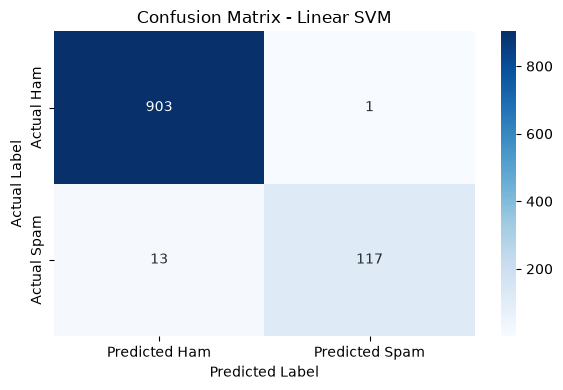

True Negatives (TN): 903
False Positives (FP): 1
False Negatives (FN): 13
True Positives (TP): 117


In [14]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Ham", "Predicted Spam"],
    yticklabels=["Actual Ham", "Actual Spam"]
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

In [15]:
# Create a results dataframe
analysis_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred,
    "Message": X_test
})

# Convert numerical labels to readable names
analysis_df["Actual"] = analysis_df["Actual"].map({
    0: "Ham",
    1: "Spam"
})

analysis_df["Predicted"] = analysis_df["Predicted"].map({
    0: "Ham",
    1: "Spam"
})

# False positives: actual Ham, predicted Spam
false_positives = analysis_df[
    (analysis_df["Actual"] == "Ham") &
    (analysis_df["Predicted"] == "Spam")
]

# False negatives: actual Spam, predicted Ham
false_negatives = analysis_df[
    (analysis_df["Actual"] == "Spam") &
    (analysis_df["Predicted"] == "Ham")
]

print("FALSE POSITIVES - Ham incorrectly classified as Spam")
print("=" * 70)

if len(false_positives) > 0:
    print(false_positives[["Message"]].head(5).to_string(index=False))
else:
    print("No false positives found.")

print("\nFALSE NEGATIVES - Spam incorrectly classified as Ham")
print("=" * 70)

if len(false_negatives) > 0:
    print(false_negatives[["Message"]].head(5).to_string(index=False))
else:
    print("No false negatives found.")

FALSE POSITIVES - Ham incorrectly classified as Spam
                                                                                                                                                    Message
K.. I yan jiu liao... Sat we can go 4 bugis vill one frm 10 to 3 den hop to parco 4 nb. Sun can go cine frm 1030 to 2, den hop to orc mrt 4 hip hop at 4...

FALSE NEGATIVES - Spam incorrectly classified as Ham
                                                                                                                                                 Message
      In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
                                                                                   Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
                                                                                                     Money i have won wini

In [16]:
fp_sample = false_positives.head(5).copy()
fp_sample["Error_Type"] = "False Positive"

fn_sample = false_negatives.head(5).copy()
fn_sample["Error_Type"] = "False Negative"

error_analysis = pd.concat([fp_sample, fn_sample])

error_analysis.to_csv("svm_error_analysis.csv", index=False)

print("Saved error analysis to svm_error_analysis.csv")
print("Number of errors displayed:", len(error_analysis))

Saved error analysis to svm_error_analysis.csv
Number of errors displayed: 6


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [19]:
# Define parameter values
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

# Create RBF SVM model
rbf_svm = SVC(kernel="rbf")

# Grid search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rbf_svm,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Train using training data only
grid_search.fit(X_train_final, y_train)

# Display best parameters and score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

# Store the best RBF model
best_rbf_model = grid_search.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 100, 'gamma': 0.01}
Best Cross-Validation F1 Score: 0.9501842718502823


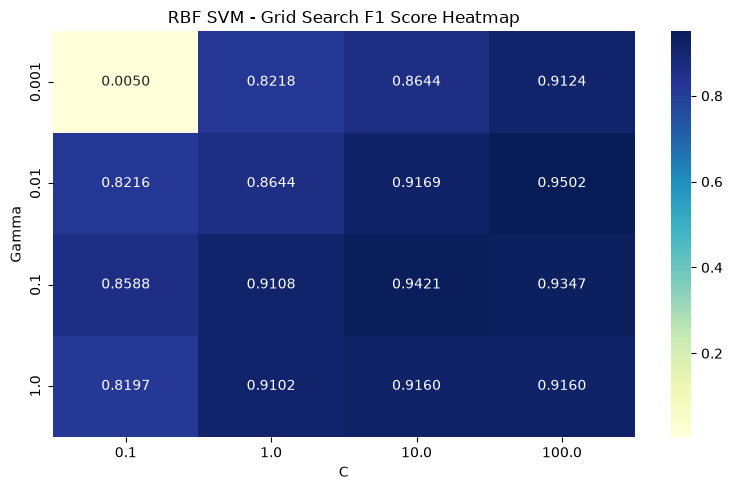

In [20]:
# Convert grid-search results into a dataframe
cv_results = pd.DataFrame(grid_search.cv_results_)

# Create a table of mean validation F1 scores
heatmap_data = cv_results.pivot(
    index="param_gamma",
    columns="param_C",
    values="mean_test_score"
)

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("RBF SVM - Grid Search F1 Score Heatmap")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.tight_layout()
plt.show()

In [21]:
# Predict test labels
linear_predictions = best_model.predict(X_test_final)
rbf_predictions = best_rbf_model.predict(X_test_final)

# Store predictions for comparison
models = {
    "Linear SVM": (best_model, linear_predictions),
    "RBF SVM": (best_rbf_model, rbf_predictions)
}

comparison_results = []

for model_name, (model, predictions) in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))

     Model  Accuracy  Precision  Recall  F1 Score
Linear SVM    0.9865     0.9915  0.9000    0.9435
   RBF SVM    0.9884     0.9836  0.9231    0.9524


In [22]:
print("LINEAR SVM")
print(classification_report(
    y_test,
    linear_predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))

print("RBF SVM")
print(classification_report(
    y_test,
    rbf_predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))

LINEAR SVM
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.99      0.90      0.94       130

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034

RBF SVM
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.98      0.92      0.95       130

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



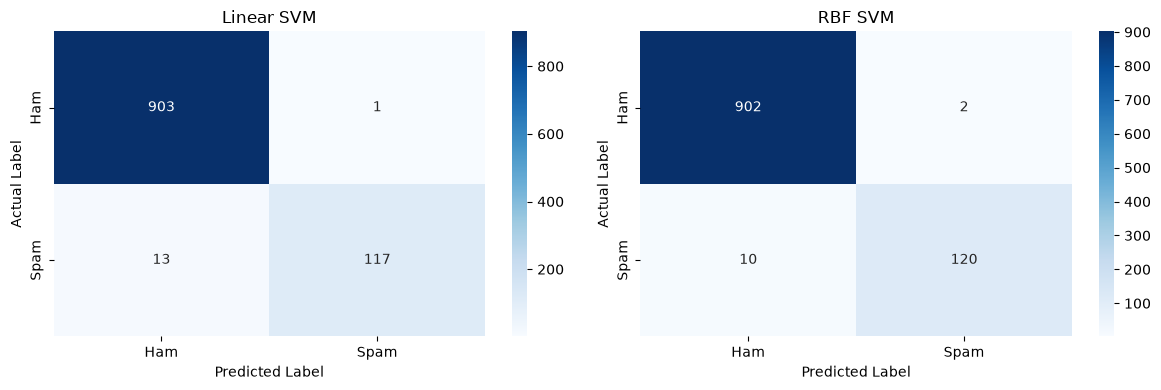

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, predictions in [
    (axes[0], "Linear SVM", linear_predictions),
    (axes[1], "RBF SVM", rbf_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [24]:
# Predict test labels
linear_predictions = best_model.predict(X_test_final)
rbf_predictions = best_rbf_model.predict(X_test_final)

# Store predictions for comparison
models = {
    "Linear SVM": (best_model, linear_predictions),
    "RBF SVM": (best_rbf_model, rbf_predictions)
}

comparison_results = []

for model_name, (model, predictions) in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, pos_label=1, zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.round(4).to_string(index=False))

     Model  Accuracy  Precision  Recall  F1 Score
Linear SVM    0.9865     0.9915  0.9000    0.9435
   RBF SVM    0.9884     0.9836  0.9231    0.9524


In [25]:
print("LINEAR SVM")
print(classification_report(
    y_test,
    linear_predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))

print("RBF SVM")
print(classification_report(
    y_test,
    rbf_predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))

LINEAR SVM
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.99      0.90      0.94       130

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034

RBF SVM
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.98      0.92      0.95       130

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



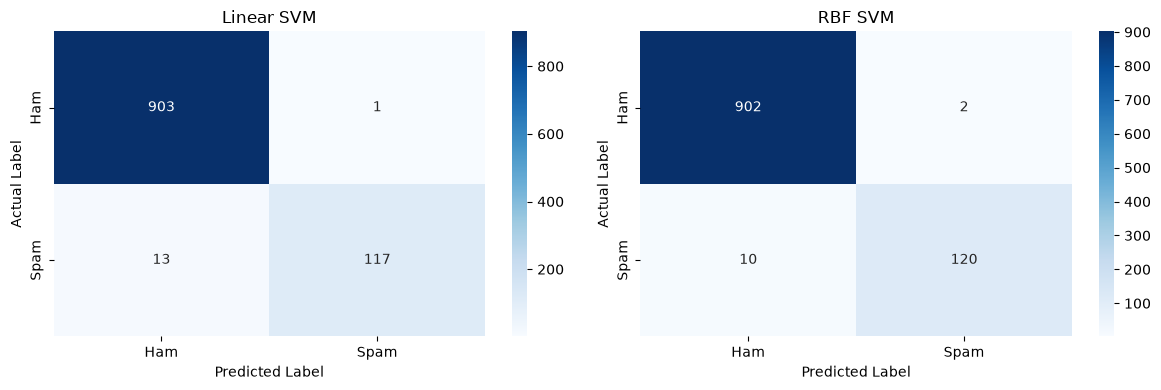

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, predictions in [
    (axes[0], "Linear SVM", linear_predictions),
    (axes[1], "RBF SVM", rbf_predictions)
]:
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

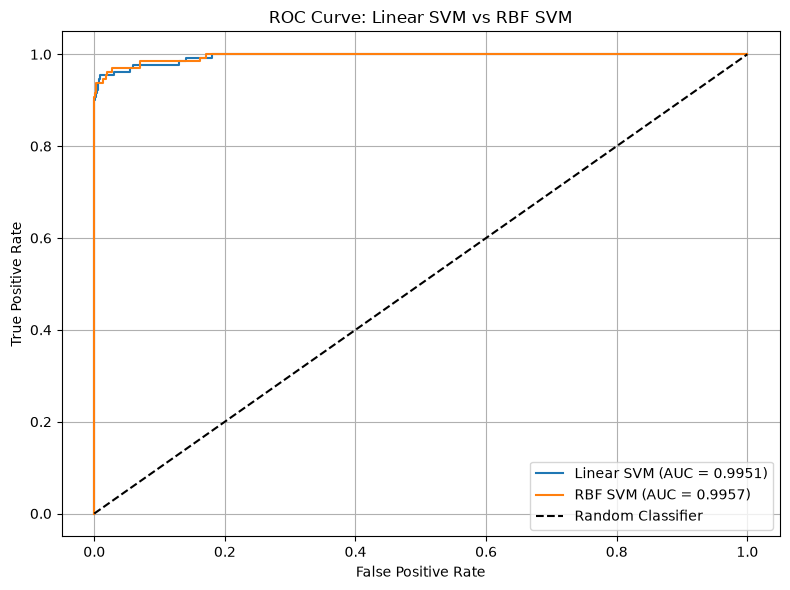

Linear SVM AUC: 0.9951
RBF SVM AUC: 0.9957


In [27]:
# Get decision scores
linear_scores = best_model.decision_function(X_test_final)
rbf_scores = best_rbf_model.decision_function(X_test_final)

# Calculate ROC curve points
fpr_linear, tpr_linear, _ = roc_curve(y_test, linear_scores)
fpr_rbf, tpr_rbf, _ = roc_curve(y_test, rbf_scores)

# Calculate AUC
auc_linear = roc_auc_score(y_test, linear_scores)
auc_rbf = roc_auc_score(y_test, rbf_scores)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_linear, tpr_linear,
    label=f"Linear SVM (AUC = {auc_linear:.4f})"
)

plt.plot(
    fpr_rbf, tpr_rbf,
    label=f"RBF SVM (AUC = {auc_rbf:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Linear SVM vs RBF SVM")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Linear SVM AUC:", round(auc_linear, 4))
print("RBF SVM AUC:", round(auc_rbf, 4))

In [28]:
print("PRODUCTION MODEL COMPARISON")
print("=" * 45)

print(comparison_df.round(4).to_string(index=False))

print("\nAUC Comparison")
print("Linear SVM:", round(auc_linear, 4))
print("RBF SVM:", round(auc_rbf, 4))

print("\nBest RBF Parameters:", grid_search.best_params_)

PRODUCTION MODEL COMPARISON
     Model  Accuracy  Precision  Recall  F1 Score
Linear SVM    0.9865     0.9915  0.9000    0.9435
   RBF SVM    0.9884     0.9836  0.9231    0.9524

AUC Comparison
Linear SVM: 0.9951
RBF SVM: 0.9957

Best RBF Parameters: {'C': 100, 'gamma': 0.01}
